# Experimental: temperature cross-section along a line

**This is an experimental example.** It samples points along a line, regrids temperature from every pressure level onto those points with [earthkit.geo.regrid](https://earthkit-geo.readthedocs.io), and plots a vertical cross-section (pressure against position along the line) with earthkit-plots. It also uses the new `earthkit.geo.polyline` module, whose interface may still change.

To make this notebook work [earthkit-data](https://earthkit-data.readthedocs.io), [earthkit-plots](https://earthkit-plots.readthedocs.io) and xarray have to be installed.

## Imports

In [1]:
from datetime import datetime, timedelta

import earthkit.data as ekd
import earthkit.geo as ekg
import earthkit.plots as ekp
import numpy as np
import xarray as xr
from earthkit.geo.distance import haversine_distance
from earthkit.geo.polyline import sample_polyline

## Load the data

The file contains surface pressure (`sp`) and temperature, wind components and vertical velocity (`t`, `u`, `v`, `w`) on the pressure levels 1000, 850, 700, 500, 400 and 300 hPa, for several forecast steps. The data is defined on a regional 1° regular latitude-longitude grid. Here is a short listing of the first fields.

In [2]:
ds = ekd.from_source("sample", "xs_pl_input.grib").to_fieldlist()
print(len(ds), "fields")
ds[:6].ls()

xs_pl_input.grib:   0%|          | 0.00/86.8k [00:00<?, ?B/s]

75 fields


,parameter.variable,time.valid_datetime,time.base_datetime,time.step,vertical.level,vertical.level_type,ensemble.member,geography.grid_type
0,u,2011-12-16,2011-12-15 12:00:00,0 days 12:00:00,1000,pressure,0,regular_ll
1,v,2011-12-16,2011-12-15 12:00:00,0 days 12:00:00,1000,pressure,0,regular_ll
2,w,2011-12-16,2011-12-15 12:00:00,0 days 12:00:00,1000,pressure,0,regular_ll
3,t,2011-12-16,2011-12-15 12:00:00,0 days 12:00:00,1000,pressure,0,regular_ll
4,u,2011-12-16,2011-12-15 12:00:00,0 days 12:00:00,850,pressure,0,regular_ll
5,v,2011-12-16,2011-12-15 12:00:00,0 days 12:00:00,850,pressure,0,regular_ll


## Select the temperature

We select temperature for the base date 2011-12-15 12 UTC and the forecast step of 12 h. This gives one field for each of the 6 pressure levels.

In [3]:
base_date = datetime(2011, 12, 15, 12)
step = timedelta(hours=12)

t = ds.sel({
    "parameter.variable": "t",
    "time.base_datetime": base_date,
    "time.step": step,
})
levels = [f.get("vertical.level") for f in t]
print(len(t), "fields, levels (hPa):", levels)

6 fields, levels (hPa): [1000, 850, 700, 500, 400, 300]


## Define the line

[sample_polyline()](https://earthkit-geo.readthedocs.io) returns the latitudes and longitudes of 200 points along the great circle between (40°N, 20°W) and (56°N, 10°E). The points are evenly spaced along the line and include both end points.

In [4]:
lats, lons = sample_polyline([40, 56], [-20, 10], n=200)
print(lats.shape, (lats[0], lons[0]), (lats[-1], lons[-1]))

(200,) (np.float64(40.0), np.float64(-20.0)) (np.float64(56.0), np.float64(10.0))


## Regrid onto the line

Each temperature field is regridded onto the 200 points, which are given as an unstructured target grid. The default linear interpolation is used. The result is a fieldlist with one field of 200 values for each pressure level. MIR may print some `ECCODES ERROR` lines about an unknown grid during this step, they come from the C library and do not stop the regridding.

In [5]:
t_line = ekg.regrid(t, out_grid={"latitudes": lats.tolist(), "longitudes": lons.tolist()})
print(len(t_line), "fields, shape of the values:", t_line[0].values.shape)

6 fields, shape of the values: (200,)


ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!


## Build an Xarray DataArray

We stack the values into a DataArray with the dimensions `level` (hPa) and `distance` (km). The distance is measured along the line from its first point, using the haversine distance (in metres, so we divide by 1000). This is valid because the line is one single great circle segment. The latitudes and longitudes of the points are stored as auxiliary coordinates of `distance`. The levels are sorted in ascending order.

In [6]:
distance = haversine_distance((lats[0], lons[0]), (lats, lons)) / 1000

da = xr.DataArray(
    np.stack([f.values for f in t_line]),
    dims=("level", "distance"),
    coords={
        "level": ("level", levels, {"units": "hPa"}),
        "distance": ("distance", distance, {"units": "km"}),
        "latitude": ("distance", lats, {"units": "degrees_north"}),
        "longitude": ("distance", lons, {"units": "degrees_east"}),
    },
    attrs={"units": "K", "long_name": "Temperature"},
    name="t",
).sortby("level")
da

<xarray.DataArray 't' (level: 6, distance: 200)> Size: 10kB
array([[234.08001709, 234.05706787, 234.03363037, ..., 212.26702881,
        211.83197021, 211.3973999 ],
       [248.38327026, 248.34664917, 248.31051636, ..., 226.85153198,
        226.81588745, 226.77975464],
       [260.21585083, 260.22317505, 260.23049927, ..., 241.19827271,
        241.15481567, 241.11135864],
       [278.45288086, 278.43530273, 278.41772461, ..., 260.02612305,
        260.05102539, 260.07592773],
       [285.29199219, 285.22021484, 285.1484375 , ..., 269.22509766,
        269.08251953, 268.94042969],
       [288.39941406, 288.375     , 288.35083008, ..., 276.41455078,
        276.34838867, 276.28222656]], shape=(6, 200))
Coordinates:
  * level      (level) int64 48B 300 400 500 700 850 1000
  * distance   (distance) float64 2kB 0.0 14.15 28.31 ... 2.802e+03 2.816e+03
    latitude   (distance) float64 2kB 40.0 40.1 40.19 40.29 ... 55.89 55.94 56.0
    longitude  (distance) float64 2kB -20.0 -19.89 -19.78 ... 9.594 9.797 10.0
Attributes:
    units:      K
    long_name:  Temperature

## Plot the cross-section

We plot the filled contours of temperature with a non-map earthkit-plots `Subplot`. The colour bar is added with the `legend()` method of the figure. The vertical axis is inverted so that 1000 hPa is at the bottom and 300 hPa at the top. The horizontal axis has 7 evenly spaced ticks, each labelled with the latitude and longitude of the nearest sampled point, rounded to whole degrees.

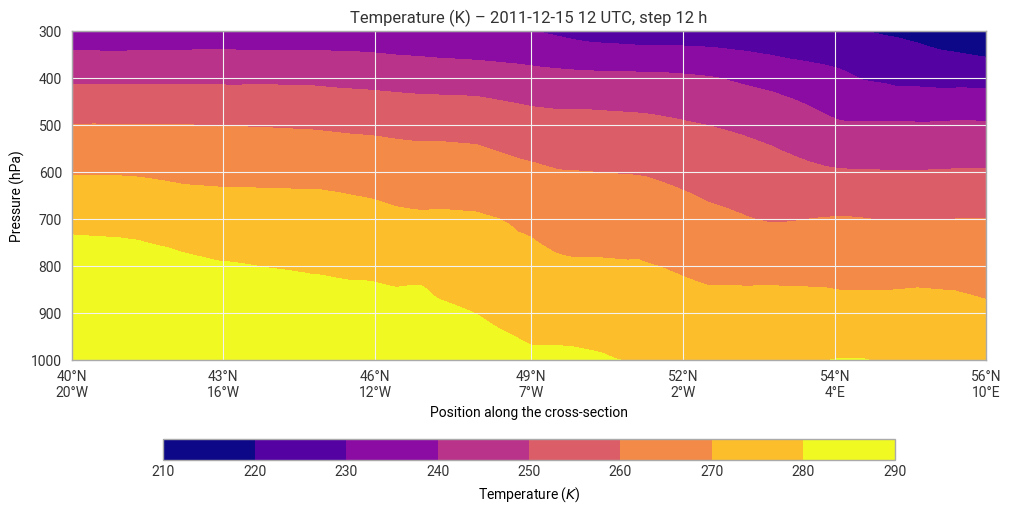

In [7]:
def fmt_lat(lat):
    lat = int(round(lat))
    return f"{abs(lat)}°N" if lat > 0 else f"{abs(lat)}°S" if lat < 0 else "0°"


def fmt_lon(lon):
    lon = int(round(lon))
    return f"{abs(lon)}°E" if lon > 0 else f"{abs(lon)}°W" if lon < 0 else "0°"


# 7 evenly spaced points along the line
idx = np.linspace(0, len(lats) - 1, 7).round().astype(int)
tick_labels = [f"{fmt_lat(lats[i])}\n{fmt_lon(lons[i])}" for i in idx]

chart = ekp.Subplot(figsize=(10, 5))
chart.contourf(da, x="distance", y="level")
chart.figure.legend()

ax = chart.ax
ax.invert_yaxis()  # 1000 hPa at the bottom, 300 hPa at the top
ax.set_xticks(distance[idx])
ax.set_xticklabels(tick_labels)
ax.set_xlabel("Position along the cross-section")
ax.set_ylabel("Pressure (hPa)")
ax.set_title(f"Temperature (K) – {base_date:%Y-%m-%d %H} UTC, step {step.total_seconds() / 3600:g} h")

chart.show()